In [ ]:
!pip install -q transformers datasets accelerate evaluate scikit-learn pandas torch

import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
import evaluate
# Set device to T4 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0)})")


Using device: cuda (Tesla T4)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/hindi_humour.csv")

# Remove rows with missing text or labels
df = df.dropna(subset=["text", "label"]).copy()

# Remove leading/trailing whitespace
df["text"] = df["text"].astype(str).str.strip()

# Remove empty text
df = df[df["text"] != ""]

# Remove exact duplicate rows only
df = df.drop_duplicates(subset=["text", "label"])

# Inspect texts that have conflicting labels
conflicts = (
    df.groupby("text")["label"]
    .nunique()
)

conflicting_texts = conflicts[conflicts > 1].index

print("Conflicting texts:", len(conflicting_texts))

# Review conflicting labels before deciding how to handle them.
# Do not blindly remove these examples.

# Stratified 80:10:10 split
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Conflicting texts: 1062
Train: 11039
Validation: 1380
Test: 1380


In [ ]:

# print(dataset["train"][0])
# print(dataset["validation"])
print(dataset["test"][10])

{'text': 'है मुझे उम लग रहा है, शांतिपूर्ण, हे-हे,', 'label': 0}


In [ ]:
# 3. Tokenization
MODEL_CHECKPOINT = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

encoded_dataset = dataset.map(
    lambda examples: tokenizer(examples['text'], truncation=True, max_length=128),
    batched=True
)

Map:   0%|          | 0/12449 [00:00<?, ? examples/s]

Map:   0%|          | 0/1556 [00:00<?, ? examples/s]

Map:   0%|          | 0/1557 [00:00<?, ? examples/s]

In [ ]:
# 4. Model Initialization
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2
).to(device)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
print(encoded_dataset["train"][0])

{'text': 'sunaharee? tumhaaree aur momm ke khyalaat kitane milate–julate hain! lekin tumhen mere talaints ke baare mein kaise pata chala?', 'label': 1, 'input_ids': [0, 36931, 3467, 7039, 32, 10029, 528, 1046, 13, 9090, 32318, 39, 311, 29610, 395, 45777, 1259, 86, 32231, 67, 1104, 461, 19309, 15531, 38, 102518, 10029, 3220, 2563, 27923, 4288, 7, 311, 62885, 13, 8172, 101498, 33156, 123679, 32, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
# 5. Metrics
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    return {
        "accuracy": accuracy_metric.compute(predictions=preds, references=labels)['accuracy'],
        "f1": f1_metric.compute(predictions=preds, references=labels, average="weighted")['f1']
    }

In [ ]:
import pandas as pd
import numpy as np
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

# 1. Load your dataset
df = pd.read_csv("/content/hindi_humour.csv")
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str)

# 2. Load the same tokenizer as your project
MODEL_CHECKPOINT = "xlm-roberta-base"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
# 3. Calculate token lengths WITHOUT truncation
texts = df["text"].tolist()
token_lengths = []

for start in range(0, len(texts), 256):
    batch = texts[start:start + 256]

    encoded = tokenizer(
        batch,
        truncation=False,
        add_special_tokens=True
    )

    token_lengths.extend(
        [len(ids) for ids in encoded["input_ids"]]
    )

df["token_length"] = token_lengths

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (561 > 512). Running this sequence through the model will result in indexing errors


In [ ]:
# 4. Calculate truncation statistics
df["will_truncate"] = df["token_length"] > MAX_LENGTH

print("Total texts:", len(df))
print("Mean token length:", round(df["token_length"].mean(), 2))
print("Median token length:", df["token_length"].median())
print("95th percentile:", df["token_length"].quantile(0.95))
print("99th percentile:", df["token_length"].quantile(0.99))
print("Maximum token length:", df["token_length"].max())

truncated_count = int(df["will_truncate"].sum())
truncation_rate = df["will_truncate"].mean() * 100

print("\nTexts exceeding 128 tokens:", truncated_count)
print(f"Truncation rate: {truncation_rate:.2f}%")

# 5. Token-length distribution
bins = [0, 32, 64, 128, float("inf")]
labels = ["1–32", "33–64", "65–128", ">128"]

df["length_bucket"] = pd.cut(
    df["token_length"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("\nToken length distribution:")
print(df["length_bucket"].value_counts(sort=False))

# 6. Create the same 80/10/10 split
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["label"]
)



Total texts: 15562
Mean token length: 40.63
Median token length: 31.0
95th percentile: 107.0
99th percentile: 176.38999999999942
Maximum token length: 926

Texts exceeding 128 tokens: 436
Truncation rate: 2.80%

Token length distribution:
length_bucket
1–32      8142
33–64     4703
65–128    2281
>128       436
Name: count, dtype: int64


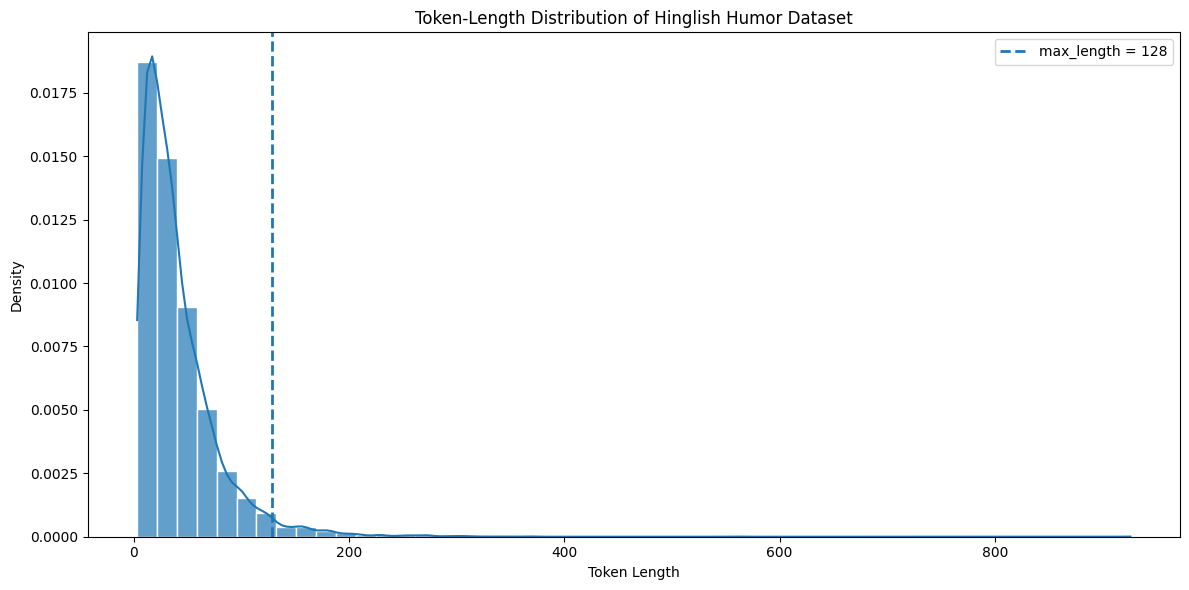

Total valid texts: 15562
Mean token length: 40.63
Median token length: 31.0
Texts exceeding 128 tokens: 436


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_plot = df.dropna(subset=["text"]).copy()
df_plot["token_length"] = df_plot["text"].astype(str).apply(
    lambda text: len(tokenizer.encode(text, add_special_tokens=True))
)

# Plot Histogram + KDE
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_plot,
    x="token_length",
    bins=50,
    kde=True,
    stat="density",
    edgecolor="white",
    alpha=0.7
)

plt.axvline(
    128,
    linestyle="--",
    linewidth=2,
    label="max_length = 128"
)

plt.title("Token-Length Distribution of Hinglish Humor Dataset")
plt.xlabel("Token Length")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

print("Total valid texts:", len(df_plot))
print("Mean token length:", round(df_plot["token_length"].mean(), 2))
print("Median token length:", df_plot["token_length"].median())
print(
    "Texts exceeding 128 tokens:",
    (df_plot["token_length"] > 128).sum()
)


In [ ]:

from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

training_args = TrainingArguments(
    output_dir="./hinglish_humor_model",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=4,
    weight_decay=0.01,
    fp16=True,  # Use only when CUDA GPU is available

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=2,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.660970,0.619004,0.650386,0.601709
2,0.619080,0.615748,0.653599,0.648875
3,0.607377,0.621753,0.642031,0.643163
4,0.590474,0.612711,0.634961,0.633887


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3116, training_loss=0.6153777468954339, metrics={'train_runtime': 1030.5291, 'train_samples_per_second': 48.321, 'train_steps_per_second': 3.024, 'total_flos': 2757181346331060.0, 'train_loss': 0.6153777468954339, 'epoch': 4.0})

In [ ]:
# 7. Train & Evaluate
trainer.train()
print("\nTest Evaluation Results:", trainer.evaluate(encoded_dataset["test"]))

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.617363,0.616672,0.639460,0.641461
2,0.596215,0.631930,0.642031,0.643163


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.617363,0.616672,0.639460,0.641461
2,0.596215,0.631930,0.642031,0.643163
3,0.583103,0.625268,0.623393,0.629628
4,0.565349,0.629821,0.616967,0.622318


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.565349,0.614792,4,0.644830,0.647182



Test Evaluation Results: {'eval_loss': 0.6147918701171875, 'eval_accuracy': 0.6448298008991651, 'eval_f1': 0.6471815009142212}


In [ ]:
# 8. Updated Quick Inference Function
def predict_humor_fixed(text_input):
    model.eval()
    inputs = tokenizer(text_input, return_tensors="pt", truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    pred_label = torch.argmax(probs, dim=-1).item()
    corrected_label = pred_label

    label_map = {0: "Non-Humorous", 1: "Humorous"}
    print(f"\nText: '{text_input}'")
    print(f"Prediction: {label_map[corrected_label]}")

# Test
predict_humor_fixed("Subah uthke coding karne ka sapna dekha tha, neend khuli toh pata chala deadline aaj hi hai! 😂")


Text: 'Subah uthke coding karne ka sapna dekha tha, neend khuli toh pata chala deadline aaj hi hai! 😂'
Prediction: Non-Humorous


# testing 100 samples from the test data


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Select 100 samples from the test dataset
test_data = encoded_dataset["test"]

n = min(100, len(test_data))
sample_data = test_data.shuffle(seed=42).select(range(n))

# 2. Generate predictions using your trained model
pred_output = trainer.predict(sample_data)

# 3. Get predicted and actual labels
y_pred = np.argmax(pred_output.predictions, axis=1)
y_true = np.array(pred_output.label_ids)

# 4. Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"Number of test samples: {n}")
print(f"Correct predictions: {(y_true == y_pred).sum()}")
print(f"Incorrect predictions: {(y_true != y_pred).sum()}")
print(f"Accuracy: {accuracy * 100:.2f}%")

# 5. Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Humorous", "Humorous"],
    zero_division=0
))

# 6. Display actual vs predicted results
label_map = {
    0: "Non-Humorous",
    1: "Humorous"
}

results_df = pd.DataFrame({
    "Text": sample_data["text"],
    "Actual Label": [label_map[int(x)] for x in y_true],
    "Predicted Label": [label_map[int(x)] for x in y_pred],
    "Correct": y_true == y_pred
})

display(results_df)


Number of test samples: 100
Correct predictions: 64
Incorrect predictions: 36
Accuracy: 64.00%

Classification Report:
              precision    recall  f1-score   support

Non-Humorous       0.71      0.66      0.68        59
    Humorous       0.56      0.61      0.58        41

    accuracy                           0.64       100
   macro avg       0.63      0.64      0.63       100
weighted avg       0.65      0.64      0.64       100



,Text,Actual Label,Predicted Label,Correct
0,3 घण्टे के अन्दर आया,Non-Humorous,Humorous,False
1,तो din क्या हुआ लटक मैं धक्का डंडा मुक्की क...,Non-Humorous,Non-Humorous,True
2,पुलीस इसामेन मेरे पाहुनचे दिली के पात चौमा मने...,Non-Humorous,Humorous,False
3,mansha tumhaaree baree mainne ek barhi 3 bah p...,Humorous,Non-Humorous,False
4,अगर सेठ सेठानी को पता चल गया तो वो क्या सोचेंगे?,Non-Humorous,Non-Humorous,True
...,...,...,...,...
95,"नहीं नहीं, इसके",Humorous,Non-Humorous,False
96,daadeemaan pramukh mainne jab sibbal moneesha...,Non-Humorous,Non-Humorous,True
97,alag to zaroor se lagega beta.,Non-Humorous,Non-Humorous,True
98,व्यवस्थित,Humorous,Non-Humorous,False
